# 01 - Exploratory Data Analysis
UCI Heart Disease (Cleveland). Plot code lives in `heartml/eda.py` so the notebook, CI and report use the same figures.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [2]:
import pandas as pd
from IPython.display import Image, display
from heartml import config
from heartml.data import load_raw, prepare
from heartml import eda

## Raw data and missing values
The raw file uses `?` for missing values.

In [3]:
raw = load_raw() if config.RAW_FILE.exists() else (prepare(), load_raw())[1]
raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [4]:
raw.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

## Cleaning
`num` (0-4) becomes binary `target`; duplicates dropped; impossible 0 values set to NaN. Imputation happens inside the model pipeline.

In [5]:
df = prepare()
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [6]:
summary = eda.run()
summary['class_counts']

{'No disease': 164, 'Disease': 139}

## Class balance
Roughly balanced (54% / 46%), so no resampling is needed; stratified splits keep the ratio.

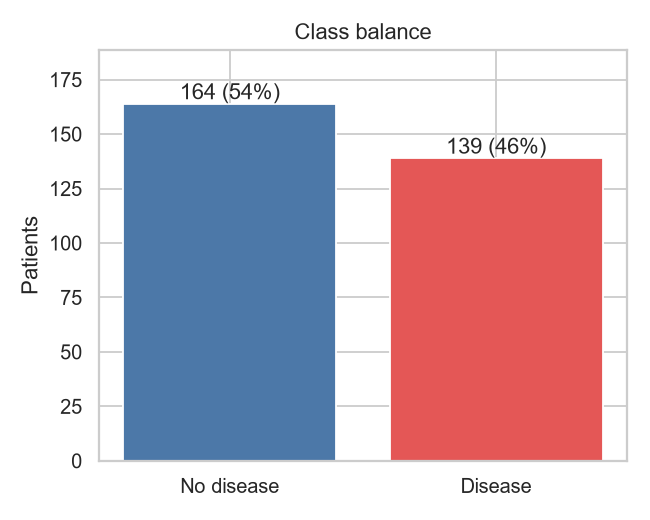

In [7]:
display(Image(config.FIGURES_DIR / 'class_balance.png'))

## Numeric features

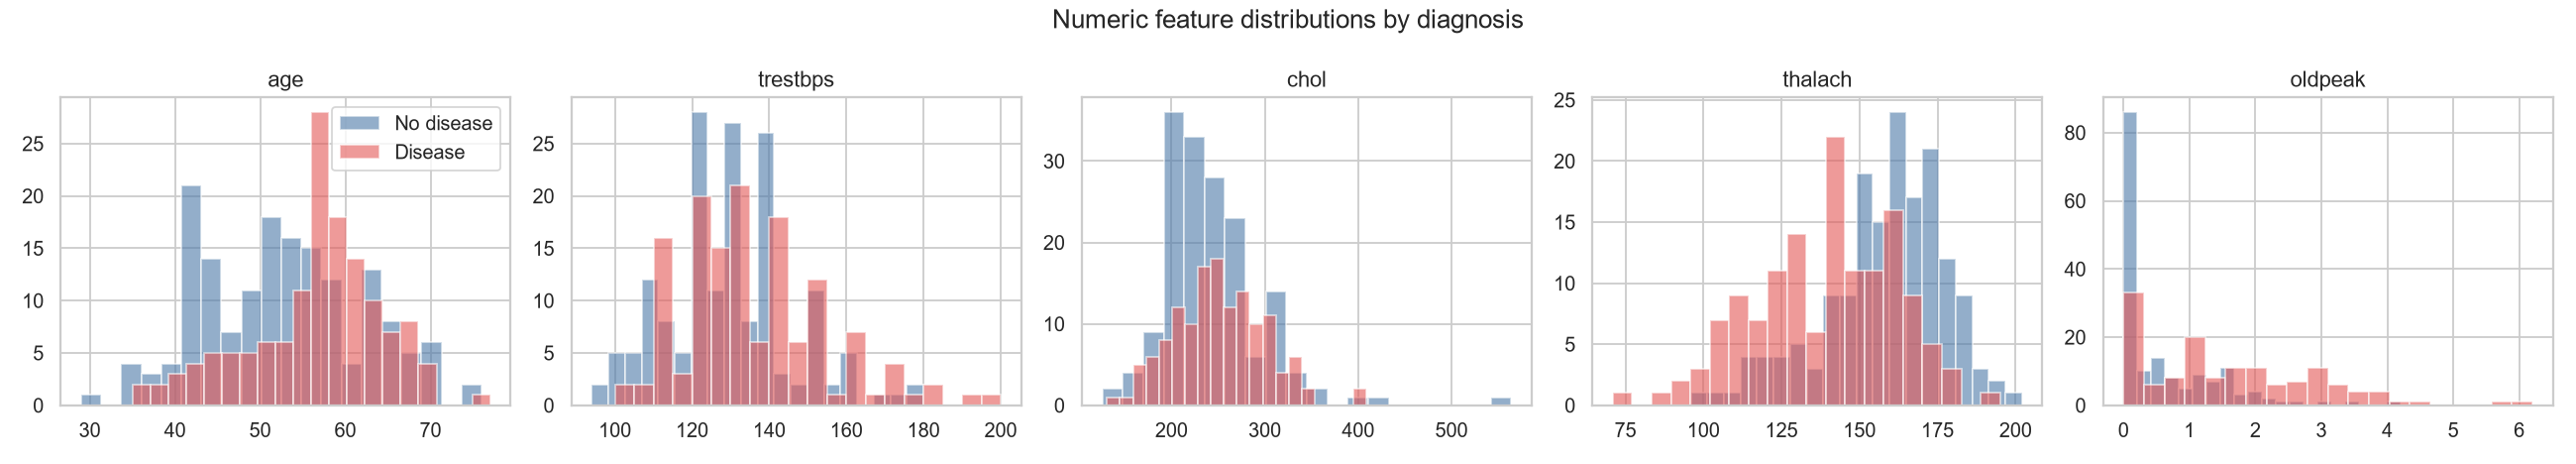

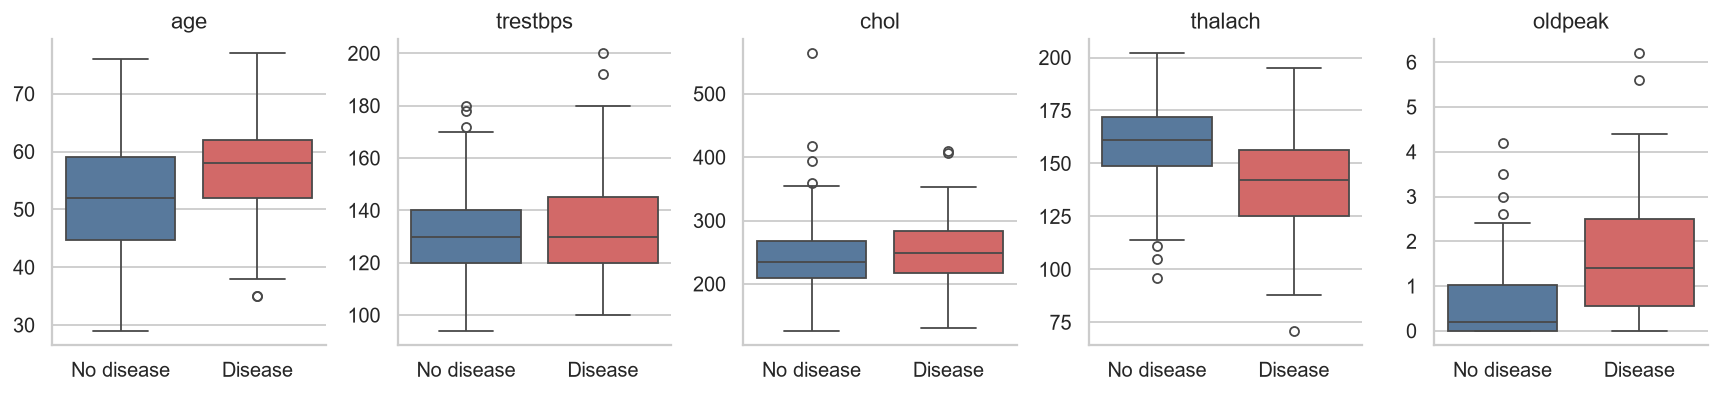

In [8]:
display(Image(config.FIGURES_DIR / 'numeric_histograms.png'))
display(Image(config.FIGURES_DIR / 'numeric_boxplots.png'))

## Categorical features: disease rate per level

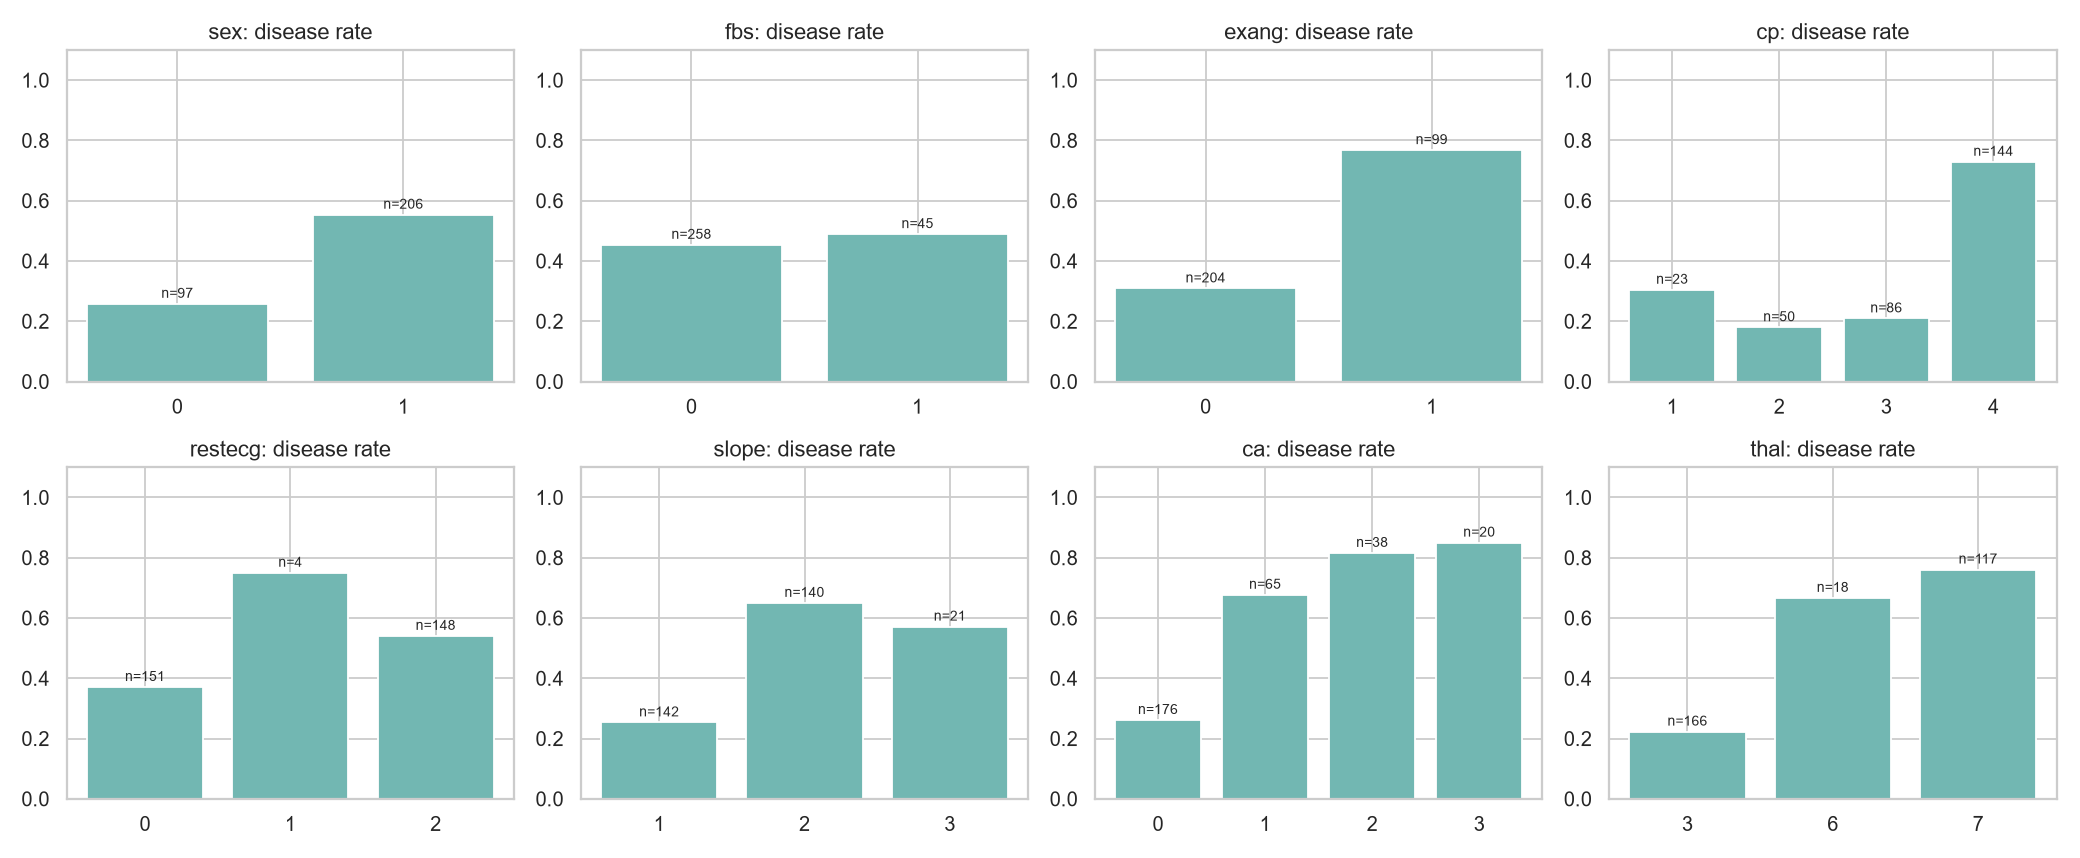

In [9]:
display(Image(config.FIGURES_DIR / 'categorical_disease_rate.png'))

## Correlations

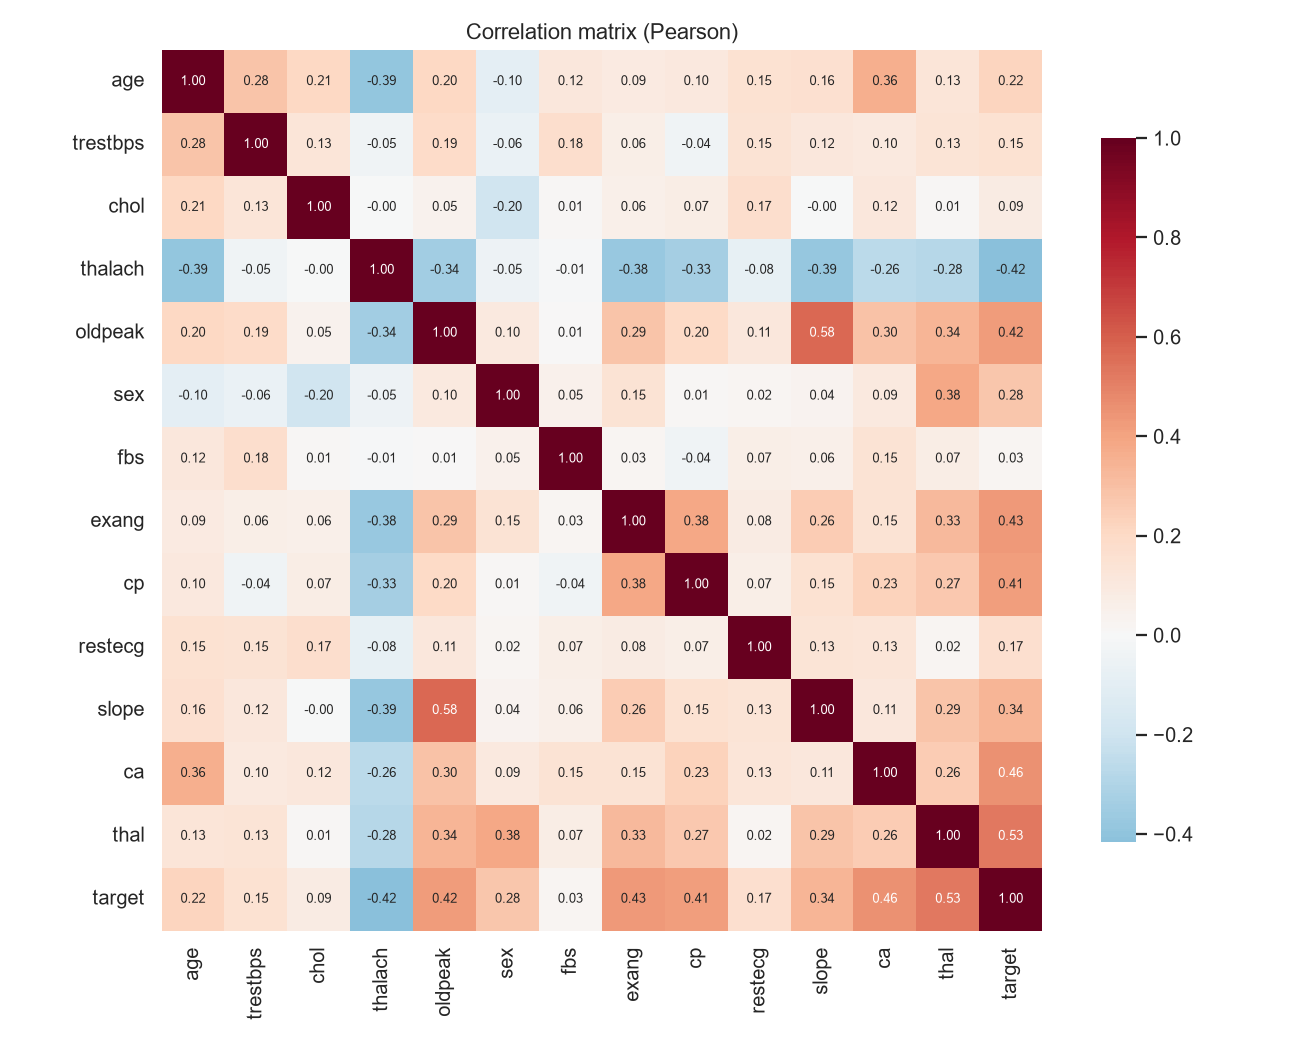

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
dtype: float64

In [10]:
display(Image(config.FIGURES_DIR / 'correlation_heatmap.png'))
pd.Series(summary['target_correlation'])